install fastai and ddgs for the session if not installed 

In [1]:
!pip install -Uqq fastai ddgs

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 242.9/242.9 kB 4.2 MB/s eta 0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 kB 823.1 kB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 53.5 MB/s eta 0:00:00:00:0100:01


ddgs - searches and returns information about images, including their URLs

fastcore.all, fastdownload - is a separate helper library made by the fast.ai team

In [2]:
from ddgs import DDGS
from fastcore.all import *

In [3]:
#Function search_images
#Parameters1: keywords - what to search for (e.g "birds photos")
#Parameters2: max_images=200 - how many results; defaults to 200
def search_images(keywords, max_images=200):
    return L(DDGS().images(keywords, max_results=max_images)).itemgot('image')

In [4]:
#Call search_images function and search for dogs save it in 1
urls = search_images('dogs', max_images=1)
urls[0]

'https://images.pexels.com/photos/1108099/pexels-photo-1108099.jpeg?cs=srgb&dl=pexels-chevanon-photography-1108099.jpg&fm=jpg'

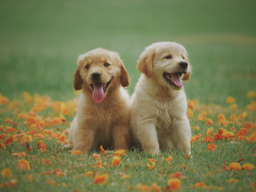

In [5]:
from fastdownload import download_url
from fastai.vision.all import *

#Downloads the first search result, saves it as dog.jpg, and shows a small preview
dest = 'dog.jpg'
download_url(urls[0], dest, show_progress=False)
im = Image.open(dest)
im.to_thumb(256, 256)

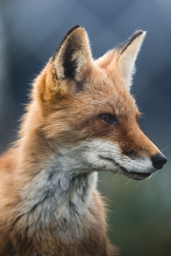

In [6]:
#Repeated with foxes
download_url(search_images('fox photos', max_images=1)[0], 'fox.jpg', show_progress=False)
Image.open('fox.jpg').to_thumb(256, 256)

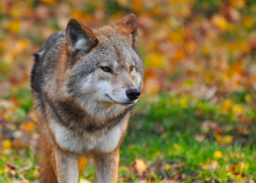

In [7]:
#Same thing as above but with different search word (wolf)
download_url(search_images('wolf photos', max_images=1)[0], 'wolf.jpg', show_progress=False)
Image.open('wolf.jpg').to_thumb(256, 256)

In [8]:
#For each category, it searches for photos, downloads them into their own folder, and shrinks them for training.
searches = ("dog", "fox", "wolf")
path = Path("animals")
for animal in searches:
    dest = (path / animal)
    dest.mkdir(exist_ok=True, parents=True)
    download_images(dest, urls=search_images(f'{animal} photo'))
    time.sleep(5)
    resize_images(path / animal, max_size=400, dest=path / animal)

In [9]:
#Delete some photos which might not download correctly: could cause model training to fail
failed = verify_images(get_image_files(path))
failed.map(Path.unlink)
len(failed)

1

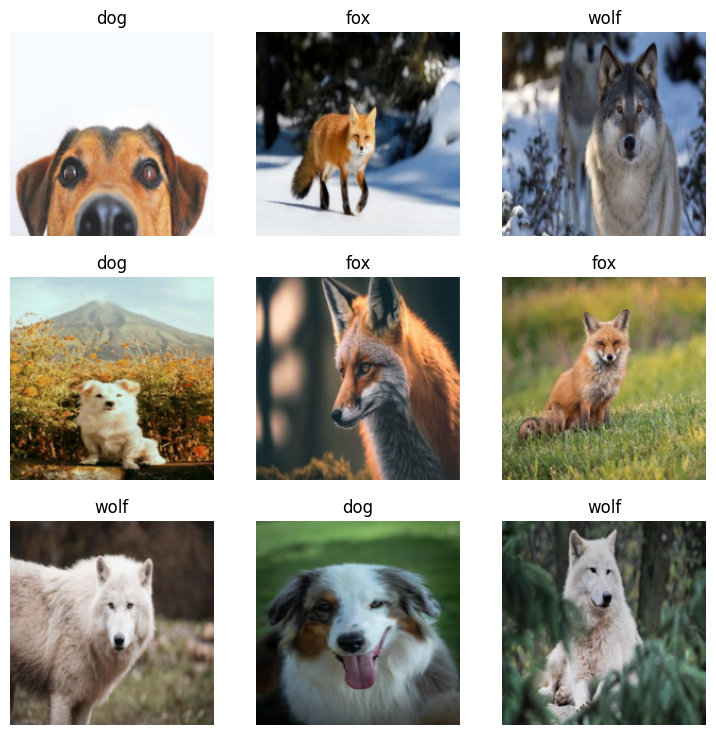

In [10]:
dls = DataBlock(
    blocks=(ImageBlock, CategoryBlock), 
    get_items=get_image_files, 
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=[Resize(192, method='squish')]
).dataloaders(path, bs=32)

dls.show_batch(max_n=9)

In [11]:
learn = vision_learner(dls, resnet18, metrics=error_rate)
learn.fine_tune(3)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 136MB/s]


epoch,train_loss,valid_loss,error_rate,time
0,2.342685,2.556122,0.700000,00:10


epoch,train_loss,valid_loss,error_rate,time
0,1.104160,1.363474,0.500000,00:15
1,0.701320,0.500321,0.200000,00:15
2,0.477473,0.328218,0.150000,00:15


In [12]:
is_dog,_,probs = learn.predict(PILImage.create('dog.jpg'))
print(f"This is a: {is_dog}.")
print(f"Probability it's a dog: {probs[0]:.4f}")

This is a: dog.
Probability it's a dog: 0.9999


In [13]:
is_fox,_,probs = learn.predict(PILImage.create('fox.jpg'))
print(f"This is a: {is_fox}.")
print(f"Probability it's a fox: {probs[1]:.4f}")

This is a: fox.
Probability it's a fox: 1.0000


In [14]:
is_wolf,_,probs = learn.predict(PILImage.create('wolf.jpg'))
print(f"This is a: {is_wolf}.")
print(f"Probability it's a wolf: {probs[2]:.4f}")

This is a: wolf.
Probability it's a wolf: 0.9530


In [15]:
def classify_url(url):
    dest = 'test.jpg'
    download_url(url, dest, show_progress=False)
    img = PILImage.create(dest)
    pred, idx, probs = learn.predict(img)

    i=0
    for animal in searches:
        print(f"{animal}: {probs[i]}")
        i += 1
    return img.to_thumb(256, 256)

dog: 0.6163291335105896
fox: 0.32535678148269653
wolf: 0.05831412225961685


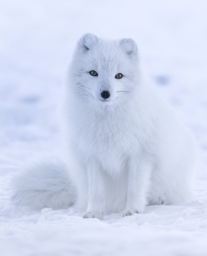

In [21]:
classify_url("https://upload.wikimedia.org/wikipedia/commons/d/dc/Vulpes_lagopus_in_Iceland_%28cropped_3%29.jpg?utm_source=en.wikipedia.org&utm_campaign=index&utm_content=original")